# Tugas 1 — Estimasi Durasi Pengiriman (Regresi Kuantil P50/P90)

Notebook ini menjalankan pipeline Tugas 1 langkah demi langkah dengan kode yang sama seperti
`python kode/run_all.py --stages regresi`. Setiap butir menjalankan modulnya di `kode/src/regresi/`,
lalu menampilkan ringkasan angka dari `kode/results/` dan grafik dari `kode/figures/`.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 1a | Audit data dan pengukuran dampak temuan | `audit.py`, `audit_dampak.py` | Rainaldi Pakpahan |
| 1b | Desain validasi berbasis waktu vs *random K-fold* | `validation.py` | Rainaldi Pakpahan |
| 1c | Perbandingan model dan *tuning* di dalam validasi waktu | `models.py` | Firdaus Arif Ramadhani |
| 1d | Rekayasa fitur dan kategori *unseen* | `features.py` | Firdaus Arif Ramadhani |
| 1e | Kalibrasi P90 dengan *conformal prediction* | `calibration.py` | Firdaus Arif Ramadhani |
| 1f | Analisis *error*, SHAP, dan `prediksi_regresi.csv` | `analysis.py` | Firdaus Arif Ramadhani |

Metrik utama: *pinball loss* kuantil 0,5 dan 0,9 (makin kecil makin baik) serta cakupan P90
(proporsi durasi aktual ≤ P90, sasaran 90%). Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan dua pembantu: `baca_hasil()` untuk membaca JSON hasil
dan `tampilkan_gambar()` untuk menampilkan grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama: str, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    gambar = PILImage.open(FIGURES_DIR / nama)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 1a. Audit Data dan Pengukuran Dampak

*Penanggung jawab: Rainaldi Pakpahan*

Audit dilakukan dengan prinsip satu fungsi untuk satu pertanyaan:

1. **Skema dan waktu (1a.1):** kecocokan kolom *train*–*test*, duplikat dan irisan ID, keacakan ID, rentang waktu.
2. **Tipe data dan *missing* (1a.2):** lokasi nilai kosong dan apakah pola kosongnya acak.
3. ***Leakage* dan pergeseran (1a.3):** *screening* semua kolom numerik terhadap target dan terhadap data uji.
4. **Target dan nilai fisik (1a.4):** durasi yang tercatat dalam menit, nilai *sentinel*, dan pemulihan `jarak_km`.
5. **Kategori dan kalender (1a.5):** kategori *unseen*, kardinalitas tinggi, efek Lebaran dan tanggal kembar.
6. **Dampak (1a.6):** setiap temuan diuji dengan model yang sama, dengan dan tanpa perbaikannya.

In [2]:
%run ../src/regresi/audit.py --save-json

=== [skema] UKURAN & DAFTAR KOLOM ===
Ukuran train         : 250,000 baris x 77 kolom
Ukuran test          : 60,000 baris x 76 kolom
Kolom hanya di train : ['durasi_jam']
Kolom hanya di test  : []



=== [duplikat] DUPLIKAT & IRISAN ID ===
Duplikat ID (train / test) : 0 / 0
Irisan ID train & test     : 0
Duplikat baris penuh train : 0

=== [id] KEACAKAN NOMOR ID ===
Korelasi ID vs urutan baris: -0.00089
Korelasi ID vs target      : -0.00200 (Spearman)

=== [waktu] RENTANG TANGGAL & VOLUME BULANAN ===
Tanggal train : 2025-01-01 s.d. 2025-08-31 (rusak=0)
Tanggal test  : 2025-09-01 s.d. 2025-10-31 (rusak=0)
Volume paket per bulan (train):
  2025-01 : 29,985
  2025-02 : 27,556
  2025-03 : 32,829
  2025-04 : 26,244
  2025-05 : 32,841
  2025-06 : 31,941
  2025-07 : 34,436
  2025-08 : 34,168
Volume paket per bulan (test):
  2025-09 : 29,638
  2025-10 : 30,362

=== [tipe] TIPE DATA KOLOM ===
Jumlah fitur numerik     : 68
Kolom teks / kategorikal : ['id_paket', 'tgl_pickup', 'layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
Tipe target durasi_jam   : float64
Beda tipe train vs test  : {}

=== [missing] NILAI KOSONG & POLA MISSINGNESS ===
Kolom dengan nilai ko


  [Detail missing: berat_kg]
    Train kosong : 13,897 baris (5.56%)
    Test kosong  : 3,265 baris (5.44%)
    % kosong per layanan     : {'ekspres': 2.55, 'hemat': 2.55, 'kargo': 32.87, 'reguler': 2.5}
    % kosong per hub_asal    : {'BDG': 5.5, 'JKT': 5.43, 'MDN': 5.8, 'MKS': 5.69, 'SBY': 5.63, 'SMG': 5.61}
    % kosong per pulau_tujuan: {'Bali-Nusa Tenggara': 5.28, 'Jawa': 5.59, 'Kalimantan': 5.36, 'Maluku': 6.02, 'Papua': 5.53, 'Sulawesi': 5.57, 'Sumatera': 5.5}
    Median durasi_jam (kosong vs terisi): 71.4 jam vs 61.1 jam
    Top-3 fitur paling berkorelasi (Spearman): {'volume_liter': 0.9248, 'jumlah_item': 0.1543, 'nilai_barang': 0.1001}



=== [leakage] SCREENING 68 KOLOM NUMERIK (KS TRAIN-VS-TEST & SPEARMAN) ===

Top 10 kolom paling beda antara Train vs Test (KS terbesar):
           kolom  ks_train_vs_test  spearman_target  train_min  train_median  train_max  test_min  test_median  test_max
     jumlah_scan            0.9154           0.7690      1.000         8.000     97.000     1.000        1.000     7.000
antrean_hub_asal            0.2611           0.1770      0.000       875.000  61805.000     0.000     2300.000 61938.000
             f30            0.2271          -0.0036     -4.053         0.500      5.436    -3.221        1.094     5.261
             f17            0.1106           0.2146      0.000         0.096      2.314     0.000        0.161     2.401
             f35            0.0901           0.1056      0.643         1.006      1.449     0.679        1.019     1.481
 hujan_tujuan_mm            0.0387           0.0304      0.000         0.000    539.900     0.000        0.000   379.700
   hujan_asal_mm

=== [target] AUDIT TARGET durasi_jam & ERROR SATUAN MENIT ===
Baris <= 0 jam                : 0
Kuantil mentah                : {'0.0': 11.6, '0.01': 23.5, '0.5': 61.7, '0.9': 117.8, '0.99': 224.7, '0.999': 3054.02, '1.0': 25452.0}
Baris > 1.000 jam             : 370 (0.148%)
Celah bersih (<=1000 vs >1000): maks sah = 693.1 jam | min ekstrem = 1272.0
Persentase kelipatan 6 (>1000): 100.0% (0,1 jam x 60 = 6)
Baris mencurigakan <= 1000    : 0
Mean target (mentah -> /60)   : 77.84 jam -> 71.27 jam
Median bersih vs ekstrem / 60 : 61.6 jam vs 64.1 jam
Median jam/scan (bersih vs/60): 7.433 vs 7.288
Grafik bukti tersimpan di     : kode/figures/task1_1a4_target_unit_error.png



=== [sentinel] CEK BATAS FISIK FITUR NUMERIK BERNAMA ===
                 kolom  train_min  train_med  train_max  test_min   test_max       cek_fisik  melanggar_tr  melanggar_te
            jam_pickup      0.000     12.000 2.3000e+01     0.000 2.3000e+01  di luar [0,23]             0             0
              jarak_km      0.000    741.600 9.9990e+03     0.000 9.9990e+03 ==0 atau >=9999          1159           307
              berat_kg      0.020      1.310 6.8334e+02     0.030 3.8508e+02             <=0             0             0
          volume_liter      0.100      5.500 4.5968e+03     0.100 2.5077e+03             <=0             0             0
           jumlah_item      1.000      2.000 1.4000e+01     1.000 1.1000e+01              <1             0             0
          nilai_barang   2000.000 276000.000 4.8400e+07  4000.000 4.8994e+07             <=0             0             0
              asuransi      0.000      0.000 1.0000e+00     0.000 1.0000e+00     bukan {0,1}    

=== [temporal] PERGESERAN BULANAN (JAN–OKT 2025) ===

1. Median f35 untuk kurir kunci (K07 bergeser di Juli; K13 baru muncul di Sep–Okt):
_ym          2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10
mitra_kurir                                                                                          
K01            0.944    0.944    0.944    0.944    0.943    0.945    0.946    0.943    0.942    0.944
K02            1.080    1.080    1.078    1.078    1.079    1.078    1.079    1.079    1.079    1.081
K07            0.985    0.987    0.985    0.986    0.988    0.984    1.282    1.278    1.280    1.282
K08            0.856    0.855    0.855    0.854    0.858    0.855    0.856    0.855    0.856    0.853
K13              NaN      NaN      NaN      NaN      NaN      NaN      NaN      NaN    1.152    1.147

2. Median durasi_jam terkoreksi untuk kurir kunci pada train (Jan–Agu):
_ym          2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07 

=== [dampak] PENGUKURAN DAMPAK KUANTITATIF (TRAIN JAN–JUN -> VAL JUL–AGU) ===

1. Dampak Leakage jumlah_scan (LightGBM Quantile):
   dengan_scan_cv_naif          -> P50=5.4229 | P90=2.9634 | cov90=0.8746
   dengan_scan_simulasi_test    -> P50=10.5022 | P90=13.4648 | cov90=0.4291
   tanpa_scan_jujur             -> P50=6.8913 | P90=4.4414 | cov90=0.8742

2. Dampak Error Satuan Target durasi_jam > 1000 (370 baris x60):
   Ridge (target mentah) -> RMSE=27.14 | MAE=18.38 | bias=+5.09 jam
   Ridge (target / 60)   -> RMSE=26.56 | MAE=16.81 | bias=-0.98 jam
   LGBM  (target mentah) -> P50=6.8831 | P90=4.4457 | cov90=0.8761
   LGBM  (target / 60)   -> P50=6.8913 | P90=4.4414 | cov90=0.8742

3. Dampak Pemulihan Sentinel jarak_km (subset sentinel val n=314):
   Sentinel mentah     -> P50=10.1310 | P90=7.6887 | MAE=20.26 jam
   Sentinel dipulihkan -> P50=8.0039 | P90=6.6483 | MAE=16.01 jam

4. Dampak Imputasi berat_kg (MAE kg pada validasi):
   Global (median vs volume*densitas): 3.996 kg -> 1.582


Ringkasan lengkap Tugas 1a tersimpan di: kode/results/task1_audit.json


Ringkasan eksperimen dampak (1a.6). Setiap baris adalah satu varian perlakuan; bandingkan *pinball*
P50/P90 dan cakupan P90 antarvarian dalam eksperimen yang sama.

In [3]:
audit = baca_hasil("task1_audit.json")
dampak = audit["langkah_1a6_pengukuran_dampak"]

baris = {}
for eksperimen, isi in dampak.items():
    if not eksperimen.startswith("exp") or not isinstance(isi, dict):
        continue
    for varian, metrik in isi.items():
        if isinstance(metrik, dict) and all(not isinstance(v, (dict, list)) for v in metrik.values()):
            baris[(eksperimen, varian)] = metrik

pd.DataFrame.from_dict(baris, orient="index")

mae_p50  p90_coverage  pinball_p50  pinball_p90      mae  mean_bias     rmse
exp1_leakage_jumlah_scan dengan_scan_cv_naif         10.8458        0.8746       5.4229       2.9634      NaN        NaN      NaN
                         dengan_scan_simulasi_test   21.0044        0.4291      10.5022      13.4648      NaN        NaN      NaN
                         tanpa_scan_jujur            13.7825        0.8742       6.8913       4.4414      NaN        NaN      NaN
exp2_satuan_target       lgbm_target_koreksi_60      13.7825        0.8742       6.8913       4.4414      NaN        NaN      NaN
                         lgbm_target_mentah          13.7662        0.8761       6.8831       4.4457      NaN        NaN      NaN
                         ridge_target_koreksi_60         NaN           NaN       8.4073          NaN  16.8146    -0.9788  26.5609
                         ridge_target_mentah             NaN           NaN       9.1913          NaN  18.3826     5.0917  27.1426
exp3_pemulihan_jarak_km  global_dipulihkan           13.7825        0.8742       6.8913       4.4414      NaN        NaN      NaN
                         global_mentah               13.7934        0.8755       6.8967       4.4367      NaN        NaN      NaN
                         subset_sentinel_dipulihkan  16.0078        0.8790       8.0039       6.6483      NaN        NaN      NaN
                         subset_sentinel_mentah      20.2621        0.8917      10.1310       7.6887      NaN        NaN      NaN
exp5_seleksi_fitur_f     hanya_10_fitur_sinyal_f     13.7368        0.8750       6.8684       4.4139      NaN        NaN      NaN
                         semua_50_fitur_f            13.7825        0.8742       6.8913       4.4414      NaN        NaN      NaN

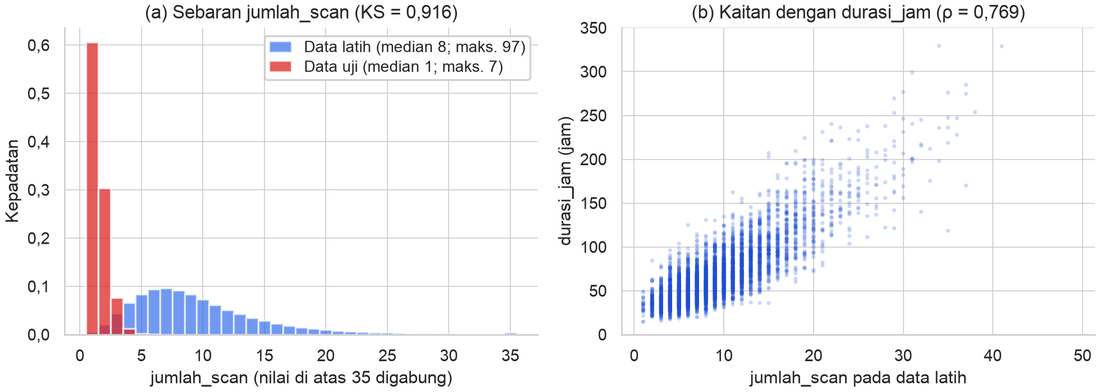

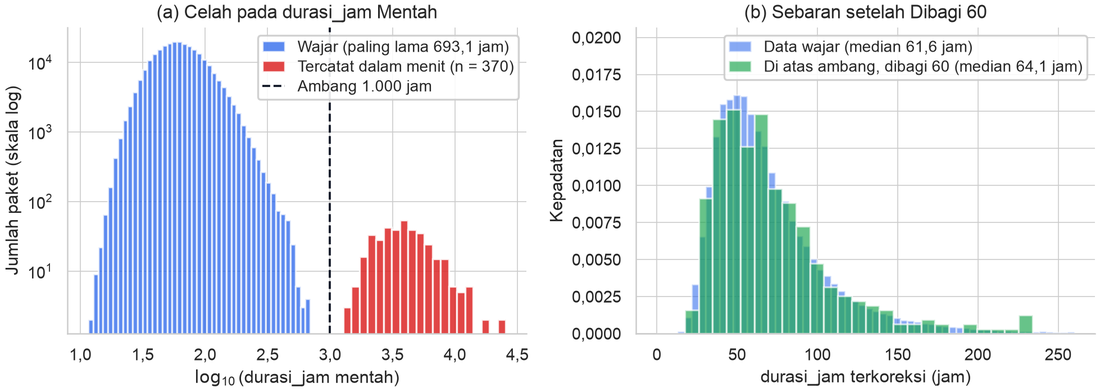

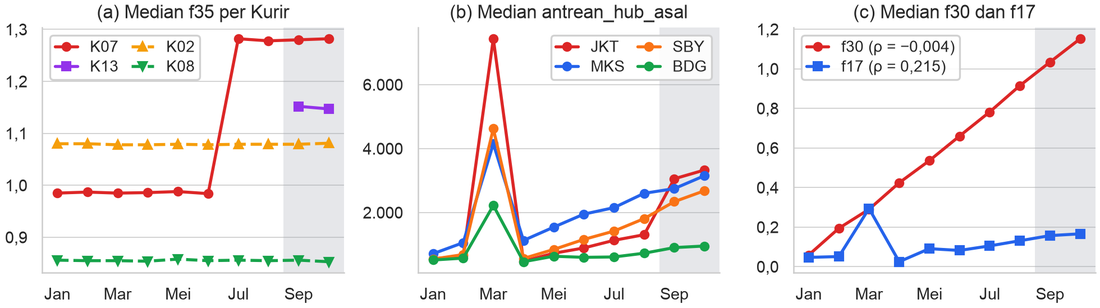

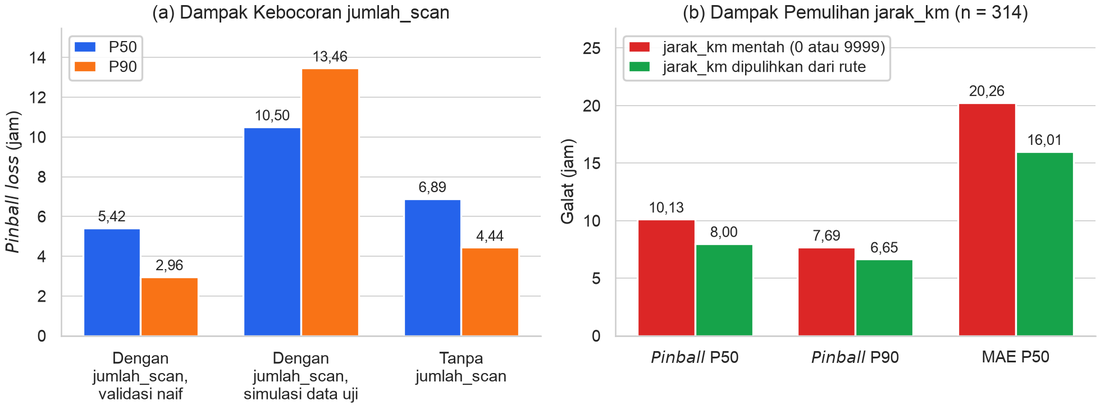

In [4]:
for nama in (
    "task1_1a3_leakage_scan.png",
    "task1_1a4_target_unit_error.png",
    "task1_1a5_temporal_shifts.png",
    "task1_1a6_dampak_audit.png",
):
    tampilkan_gambar(nama)

## 1b. Desain Validasi Berbasis Waktu

*Penanggung jawab: Rainaldi Pakpahan*

Data uji berada pada September–Oktober 2025, sehingga validasi meniru pemakaian nyata: model dilatih
pada bulan-bulan sebelumnya lalu memprediksi dua bulan berikutnya (*expanding-window time-based CV*,
3 *fold*). Skema ini dibandingkan dengan *random* 5-*fold* CV memakai model dan fitur yang identik
untuk menunjukkan seberapa optimistis validasi acak.

In [5]:
%run ../src/regresi/validation.py

[START] Evaluasi Expanding-Window Time-Based CV (3 fold)


[DONE]  Evaluasi Expanding-Window Time-Based CV (3 fold) (46.10s)
[START] Evaluasi Random 5-Fold CV


[DONE]  Evaluasi Random 5-Fold CV (104.90s)
=== [time] EXPANDING-WINDOW TIME-BASED CV (3 FOLD x 2 BULAN) ===
  Fold 1 (Mar–Apr)   (tr= 57,541, va=59,073) -> P50=7.7259 | P90=5.5699 | cov90=79.72% | MAE=15.45
  Fold 2 (Mei–Jun)   (tr=116,614, va=64,782) -> P50=6.4519 | P90=4.2150 | cov90=90.64% | MAE=12.90
  Fold 3 (Jul–Agu)   (tr=181,396, va=68,604) -> P50=6.8813 | P90=4.4086 | cov90=87.57% | MAE=13.76
  Rata-rata Time CV -> P50=7.0197 (±0.5292) | P90=4.7312 (±0.5983) | cov90=85.98%

=== [random] RANDOM 5-FOLD CV (SHUFFLE=TRUE) ===
  Random Fold 1      (tr=200,000, va=50,000) -> P50=6.6007 | P90=4.2648 | cov90=88.74% | MAE=13.20
  Random Fold 2      (tr=200,000, va=50,000) -> P50=6.7105 | P90=4.3979 | cov90=88.35% | MAE=13.42
  Random Fold 3      (tr=200,000, va=50,000) -> P50=6.6454 | P90=4.3123 | cov90=88.64% | MAE=13.29
  Random Fold 4      (tr=200,000, va=50,000) -> P50=6.6562 | P90=4.2845 | cov90=88.45% | MAE=13.31
  Random Fold 5      (tr=200,000, va=50,000) -> P50=6.5994 | P90=4


Grafik tersimpan di : kode/figures/task1_1b_validation_comparison.png
Hasil JSON tersimpan: kode/results/task1_validation.json


**Ringkasan rata-rata dan simpangan baku per skema**

,mae_p50_mean,mae_p50_std,p90_coverage_mean,p90_coverage_std,pinball_p50_mean,pinball_p50_std,pinball_p90_mean,pinball_p90_std
Time CV (3 fold),14.0393,1.0584,0.8598,0.0460,7.0197,0.5292,4.7312,0.5983
Random 5-fold,13.2849,0.0820,0.8855,0.0014,6.6424,0.0410,4.3004,0.0539


**Rincian per fold pada Time CV**

,fold,mae_p50,n_train,n_val,p90_coverage,periode_train,periode_val,pinball_p50,pinball_p90
0,Fold 1 (Mar–Apr),15.4517,57541,59073,0.7972,2025-01-01..2025-02-28,2025-03-01..2025-04-30,7.7259,5.5699
1,Fold 2 (Mei–Jun),12.9038,116614,64782,0.9064,2025-01-01..2025-04-30,2025-05-01..2025-06-30,6.4519,4.2150
2,Fold 3 (Jul–Agu),13.7625,181396,68604,0.8757,2025-01-01..2025-06-30,2025-07-01..2025-08-31,6.8813,4.4086


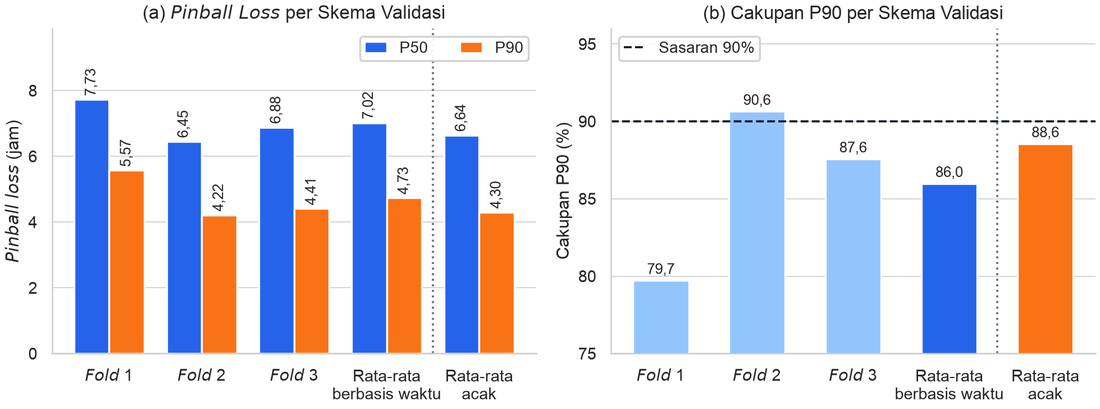

In [6]:
validasi = baca_hasil("task1_validation.json")
display(Markdown("**Ringkasan rata-rata dan simpangan baku per skema**"))
display(tabel_metrik({
    "Time CV (3 fold)": validasi["time_based_cv"]["ringkasan"],
    "Random 5-fold": validasi["random_kfold_cv"]["ringkasan"],
}))
display(Markdown("**Rincian per fold pada Time CV**"))
display(pd.DataFrame(validasi["time_based_cv"]["per_fold"]))
tampilkan_gambar("task1_1b_validation_comparison.png")

## 1c. Perbandingan Model dan *Tuning* di Dalam Validasi Waktu

*Penanggung jawab: Firdaus Arif Ramadhani*

Satu *baseline* dan empat keluarga model dibandingkan pada skema validasi 1b; semua *tuning* dilakukan
di dalam *fold* waktu agar tidak bocor:

0. *Baseline* kuantil empiris per `(layanan, pulau_tujuan)`.
1. Ridge pada `log(durasi_jam)` dengan kuantil residual per layanan.
2. LightGBM *quantile*.
3. CatBoost *MultiQuantile*.
4. XGBoost *MultiQuantile*.
5. *Ensemble* konveks dari model terbaik, dengan bobot terpisah untuk P50 dan P90.

Prediksi *out-of-fold* disimpan ke `kode/cache/` dan dipakai lagi oleh butir 1e dan 1f.

In [7]:
%run ../src/regresi/models.py

[START] Menyiapkan 3 fold Time CV dengan feature pipeline anti-leakage


[DONE]  Menyiapkan 3 fold Time CV dengan feature pipeline anti-leakage (4.20s)
[START] Model 0: Baseline Group Quantile (layanan x pulau_tujuan)


[DONE]  Model 0: Baseline Group Quantile (layanan x pulau_tujuan) (0.24s)
[START] Model 1: Log-Target Ridge Quantile (tuning alpha)


[DONE]  Model 1: Log-Target Ridge Quantile (tuning alpha) (15.25s)
[START] Model 2: LightGBM Quantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 2: LightGBM Quantile (tuning di dalam 3-fold Time CV) (320.30s)
[START] Model 3: CatBoost MultiQuantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 3: CatBoost MultiQuantile (tuning di dalam 3-fold Time CV) (261.96s)
[START] Model 4: XGBoost MultiQuantile (tuning di dalam 3-fold Time CV)


[DONE]  Model 4: XGBoost MultiQuantile (tuning di dalam 3-fold Time CV) (73.74s)



================ RINGKASAN MODEL TUGAS 1c (TIME CV) ================
  baseline     | Mean3F: P50=10.4331, P90=6.4320, cov=88.05% | Fold3(Jul-Agu): P50=10.4868, P90=6.4582, cov=88.91%
  log_ridge    | Mean3F: P50=7.2914, P90=4.6816, cov=87.08% | Fold3(Jul-Agu): P50=7.0002, P90=4.3816, cov=89.03%
  lgbm         | Mean3F: P50=7.0020, P90=4.6643, cov=85.13% | Fold3(Jul-Agu): P50=6.7549, P90=4.2688, cov=87.56%
  catboost     | Mean3F: P50=6.9916, P90=4.6008, cov=85.40% | Fold3(Jul-Agu): P50=6.6918, P90=4.2098, cov=87.75%
  xgboost      | Mean3F: P50=7.1781, P90=4.7789, cov=85.93% | Fold3(Jul-Agu): P50=6.9269, P90=4.4119, cov=88.07%
  ensemble     | Mean3F: P50=6.9557, P90=4.5477, cov=86.52% | Fold3(Jul-Agu): P50=6.6932, P90=4.1998, cov=88.87%

Bobot Ensemble Final (3-fold OOF):
  P50: {'log_ridge': 0.0794, 'lgbm': 0.4232, 'catboost': 0.4974, 'xgboost': 0.0}
  P90: {'log_ridge': 0.3407, 'lgbm': 0.1143, 'catboost': 0.5451, 'xgboost': 0.0}

Grafik: kode/figures/task1_1c_model_comparison.png


,pinball_p50_mean,pinball_p90_mean,p90_coverage_mean,fold3_pinball_p50,fold3_pinball_p90,fold3_p90_coverage
baseline,10.4331,6.4320,0.8805,10.4868,6.4582,0.8891
catboost,6.9916,4.6008,0.8540,6.6918,4.2098,0.8775
ensemble,6.9557,4.5477,0.8652,6.6932,4.1998,0.8887
lgbm,7.0020,4.6643,0.8513,6.7549,4.2688,0.8756
log_ridge,7.2914,4.6816,0.8708,7.0002,4.3816,0.8903
xgboost,7.1781,4.7789,0.8593,6.9269,4.4119,0.8807


**Bobot *ensemble* final (dioptimalkan pada OOF 3 fold)**

,P50,P90
catboost,0.4974,0.5451
lgbm,0.4232,0.1143
log_ridge,0.0794,0.3407
xgboost,0.0000,0.0000


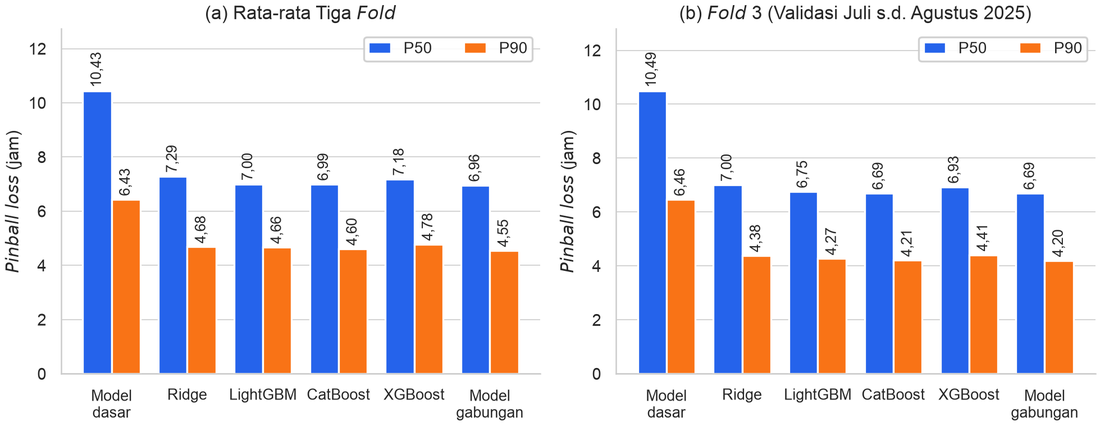

In [8]:
model = baca_hasil("task1_models.json")
kolom = [
    "pinball_p50_mean", "pinball_p90_mean", "p90_coverage_mean",
    "fold3_pinball_p50", "fold3_pinball_p90", "fold3_p90_coverage",
]
display(tabel_metrik({nama: isi["ringkasan"] for nama, isi in model["models"].items()}, kolom))
ensemble = model["models"]["ensemble"]
display(Markdown("**Bobot *ensemble* final (dioptimalkan pada OOF 3 fold)**"))
display(pd.DataFrame({
    "P50": ensemble["weights_p50_final_all3"],
    "P90": ensemble["weights_p90_final_all3"],
}))
tampilkan_gambar(model["figure"])

## 1d. Rekayasa Fitur dan Kategori *Unseen*

*Penanggung jawab: Firdaus Arif Ramadhani*

Fitur dibangun dari waktu *pickup* (tanpa informasi masa depan). Dua tantangan kategori ditangani:

- **Kardinalitas tinggi** (`kota_tujuan` dan rute `hub_asal × kota_tujuan`): *hierarchical smoothed
  target encoding* *out-of-fold* dengan *shrinkage* bertingkat ke `pulau_tujuan` lalu ke rata-rata global.
- **Kurir *unseen*** (`mitra_kurir = K13` hanya ada di data uji): diuji lewat simulasi
  *leave-one-courier-out*; tiga kurir disembunyikan dari data latih lalu tiga strategi dibandingkan.

In [9]:
%run ../src/regresi/features.py --test-unseen

[START] Simulasi Leave-One-Courier-Out (K08, K02, K07)


[DONE]  Simulasi Leave-One-Courier-Out (K08, K02, K07) (46.13s)

=== HASIL SIMULASI KURIR UNSEEN (TUGAS 1d) ===
  tanpa_f35_fallback_global    -> P50=8.5449 | P90=5.8559 | cov90=74.54%
      K08 (f35=0.855): P50=6.908, bias=+7.55 jam
      K02 (f35=1.079): P50=7.230, bias=-4.56 jam
      K07 (f35=1.280): P50=11.986, bias=-15.88 jam
  mitra_kurir_plus_f35         -> P50=8.2899 | P90=5.4851 | cov90=77.07%
      K08 (f35=0.855): P50=6.641, bias=+6.64 jam
      K02 (f35=1.079): P50=7.176, bias=-4.17 jam
      K07 (f35=1.280): P50=11.434, bias=-14.77 jam
  hanya_f35_tanpa_id_kurir     -> P50=7.7243 | P90=5.0598 | cov90=80.77%
      K08 (f35=0.855): P50=6.184, bias=+4.95 jam
      K02 (f35=1.079): P50=6.968, bias=-2.59 jam
      K07 (f35=1.280): P50=10.228, bias=-11.27 jam


Kurir yang disembunyikan: K08, K02, K07
Baris validasi kurir unseen: 18,534


,overall_p90_coverage,overall_pinball_p50,overall_pinball_p90
hanya_f35_tanpa_id_kurir,0.8077,7.7243,5.0598
mitra_kurir_plus_f35,0.7707,8.2899,5.4851
tanpa_f35_fallback_global,0.7454,8.5449,5.8559


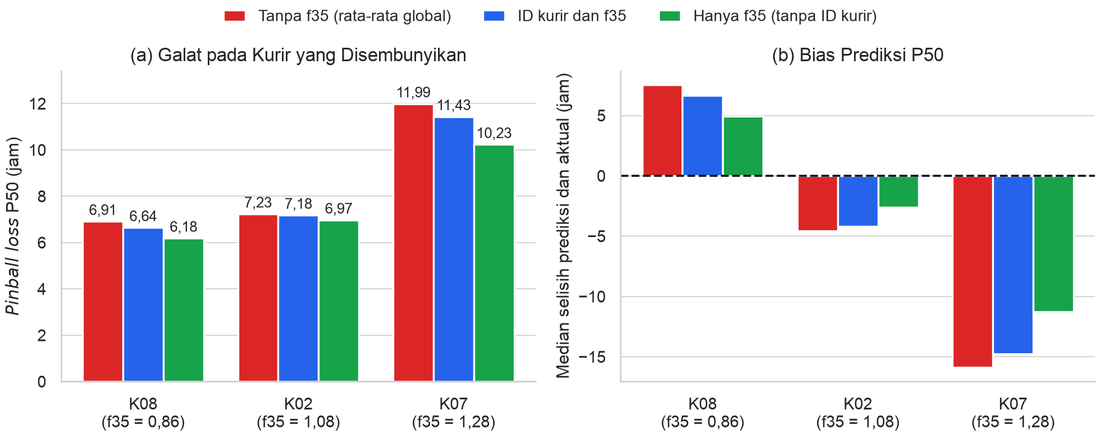

In [10]:
kurir = baca_hasil("task1_unseen_courier.json")
print("Kurir yang disembunyikan:", ", ".join(kurir["heldout_couriers"]))
print(f"Baris validasi kurir unseen: {kurir['n_val_unseen_rows']:,}")
display(tabel_metrik(
    {nama: {k: v for k, v in isi.items() if k != "per_kurir_unseen"} for nama, isi in kurir["strategi"].items()}
))
tampilkan_gambar(kurir["figure"])